# Download Hawthorne Solar Radiation Data

Use this notebook to extend `data/SR_Data/SR_Data_HW.csv` with hourly Hawthorne (`QHW`) solar radiation data from Synoptic/MesoWest. By default it starts after the last timestamp already in the CSV and downloads through `2025-12-31 23:00` local time.

Set `MESOWEST_TOKEN` in your shell, repo `.env`, `Notebooks/.env`, or `Synoptic/.env` before running the download cell.

In [1]:
from datetime import timedelta
import os
from pathlib import Path
from time import sleep

import pandas as pd
import requests
from dotenv import load_dotenv

TIMEZONE = "America/Denver"
BASE_URL = "https://api.synopticdata.com/v2/stations/timeseries"

STATION_ID = "QHW"  # Hawthorne
VARIABLE = "solar_radiation"
VALUE_COLUMN = "solar_radiation_w_m2"

START_FALLBACK = pd.Timestamp("2021-09-01 09:00:00")
END_DATE = pd.Timestamp("2025-12-31 23:00:00")

OVERWRITE_EXISTING = False
REQUEST_CHUNK_DAYS = 31
REQUEST_PAUSE_SECONDS = 1


def find_repo_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / ".git").exists() or (candidate / "data").exists():
            return candidate
    raise FileNotFoundError("Could not find the project root from the current working directory.")


REPO_ROOT = find_repo_root()
SR_PATH = REPO_ROOT / "data" / "SR_Data" / "SR_Data_HW.csv"

for env_path in [REPO_ROOT / ".env", REPO_ROOT / "Notebooks" / ".env", REPO_ROOT / "Synoptic" / ".env"]:
    if env_path.exists():
        load_dotenv(env_path, override=False)

MESOWEST_TOKEN = os.getenv("MESOWEST_TOKEN")
if not MESOWEST_TOKEN:
    raise EnvironmentError("Missing MESOWEST_TOKEN. Add it to .env or export it before running this notebook.")

print(f"Repo root: {REPO_ROOT}")
print(f"SR output: {SR_PATH}")

Repo root: /Users/isaacsudweeks/Desktop/Work/Improved_Isopleths
SR output: /Users/isaacsudweeks/Desktop/Work/Improved_Isopleths/data/SR_Data/SR_Data_HW.csv


In [2]:
def load_existing_sr(path: Path) -> pd.Series:
    if not path.exists():
        return pd.Series(dtype="float64", name=VALUE_COLUMN)

    existing = pd.read_csv(path, index_col=0, parse_dates=True)
    if VALUE_COLUMN not in existing.columns:
        raise ValueError(f"Expected column {VALUE_COLUMN!r} in {path}. Found: {list(existing.columns)}")

    series = pd.to_numeric(existing[VALUE_COLUMN], errors="coerce")
    series.index = pd.DatetimeIndex(series.index).floor("h")
    return series.sort_index().rename(VALUE_COLUMN)


def iter_chunks(start: pd.Timestamp, end: pd.Timestamp, days: int = REQUEST_CHUNK_DAYS):
    chunk_start = pd.Timestamp(start)
    end = pd.Timestamp(end)
    while chunk_start <= end:
        chunk_end = min(chunk_start + pd.Timedelta(days=days) - pd.Timedelta(hours=1), end)
        yield chunk_start, chunk_end
        chunk_start = chunk_end + pd.Timedelta(hours=1)


def fetch_synoptic_series(token: str, station: str, start: pd.Timestamp, end: pd.Timestamp) -> pd.Series:
    params = {
        "token": token,
        "stid": station,
        "start": start.strftime("%Y%m%d%H%M"),
        "end": end.strftime("%Y%m%d%H%M"),
        "vars": VARIABLE,
        "obtimezone": "local",
        "output": "json",
    }

    response = requests.get(BASE_URL, params=params, timeout=60)
    response.raise_for_status()
    payload = response.json()

    summary = payload.get("SUMMARY", {})
    if summary.get("RESPONSE_CODE") != 1 or not payload.get("STATION"):
        raise RuntimeError(f"Synoptic request failed: {summary.get('RESPONSE_MESSAGE', payload)}")

    observations = payload["STATION"][0].get("OBSERVATIONS", {})
    timestamps = observations.get("date_time", [])
    values = observations.get(f"{VARIABLE}_set_1", observations.get(VARIABLE, []))

    if not timestamps:
        return pd.Series(dtype="float64", name=VALUE_COLUMN)

    parsed_time = pd.to_datetime(timestamps, errors="coerce", utc=True)
    local_index = parsed_time.tz_convert(TIMEZONE).tz_localize(None)
    series = pd.Series(pd.to_numeric(values, errors="coerce"), index=local_index, name=VALUE_COLUMN)
    series = series[series.index.notna()].sort_index()
    series.index = pd.DatetimeIndex(series.index).floor("h")
    return series[~series.index.duplicated(keep="last")]


def fetch_missing_sr(token: str, start: pd.Timestamp, end: pd.Timestamp) -> pd.Series:
    pieces = []
    chunks = list(iter_chunks(start, end))
    for index, (chunk_start, chunk_end) in enumerate(chunks, start=1):
        print(f"[{index}/{len(chunks)}] {chunk_start} to {chunk_end}")
        pieces.append(fetch_synoptic_series(token, STATION_ID, chunk_start, chunk_end))
        if index < len(chunks):
            sleep(REQUEST_PAUSE_SECONDS)

    if not pieces:
        return pd.Series(dtype="float64", name=VALUE_COLUMN)
    return pd.concat(pieces).sort_index().rename(VALUE_COLUMN)


existing_sr = load_existing_sr(SR_PATH)
print(f"Existing rows: {len(existing_sr):,}")
if len(existing_sr):
    print(f"Existing coverage: {existing_sr.index.min()} to {existing_sr.index.max()}")

Existing rows: 36,331
Existing coverage: 2021-09-01 09:00:00 to 2025-10-24 03:00:00


In [3]:
if OVERWRITE_EXISTING or existing_sr.empty:
    download_start = START_FALLBACK
else:
    download_start = existing_sr.index.max() + pd.Timedelta(hours=1)

download_end = END_DATE

if download_start > download_end:
    print(f"No download needed. Existing data already reaches {existing_sr.index.max()}.")
    downloaded_sr = pd.Series(dtype="float64", name=VALUE_COLUMN)
else:
    print(f"Downloading {STATION_ID} {VARIABLE} from {download_start} through {download_end}.")
    downloaded_sr = fetch_missing_sr(MESOWEST_TOKEN, download_start, download_end)
    print(f"Downloaded rows: {len(downloaded_sr):,}")

combined_sr = pd.concat([existing_sr, downloaded_sr]).sort_index()
combined_sr = combined_sr[~combined_sr.index.duplicated(keep="last")].rename(VALUE_COLUMN)
combined_sr = combined_sr.loc[combined_sr.index <= END_DATE]

SR_PATH.parent.mkdir(parents=True, exist_ok=True)
combined_sr.to_csv(SR_PATH)

print(f"Saved {len(combined_sr):,} rows to {SR_PATH}")
print(f"Final coverage: {combined_sr.index.min()} to {combined_sr.index.max()}")

[1/3] 2025-10-24 04:00:00 to 2025-11-24 03:00:00
[2/3] 2025-11-24 04:00:00 to 2025-12-25 03:00:00
[3/3] 2025-12-25 04:00:00 to 2025-12-31 23:00:00
Downloaded rows: 1,651
Saved 37,972 rows to /Users/isaacsudweeks/Desktop/Work/Improved_Isopleths/data/SR_Data/SR_Data_HW.csv
Final coverage: 2021-09-01 09:00:00 to 2025-12-31 16:00:00


In [4]:
expected_hours = pd.date_range(combined_sr.index.min(), END_DATE, freq="h")
missing_hours = expected_hours.difference(combined_sr.index)

summary = pd.DataFrame(
    {
        "metric": ["rows", "start", "end", "missing_hours_to_end_date", "non_null_values"],
        "value": [
            f"{len(combined_sr):,}",
            combined_sr.index.min(),
            combined_sr.index.max(),
            f"{len(missing_hours):,}",
            f"{combined_sr.notna().sum():,}",
        ],
    }
)
display(summary)

if len(missing_hours):
    display(pd.Series(missing_hours[:25], name="first_missing_hours"))

,metric,value
0,rows,"37,972"
1,start,2021-09-01 09:00:00
2,end,2025-12-31 16:00:00
3,missing_hours_to_end_date,11
4,non_null_values,"37,897"


0    2022-03-13 02:00:00
1    2023-03-12 02:00:00
2    2024-03-10 02:00:00
3    2025-03-09 02:00:00
4    2025-12-31 17:00:00
5    2025-12-31 18:00:00
6    2025-12-31 19:00:00
7    2025-12-31 20:00:00
8    2025-12-31 21:00:00
9    2025-12-31 22:00:00
10   2025-12-31 23:00:00
Name: first_missing_hours, dtype: datetime64[us]

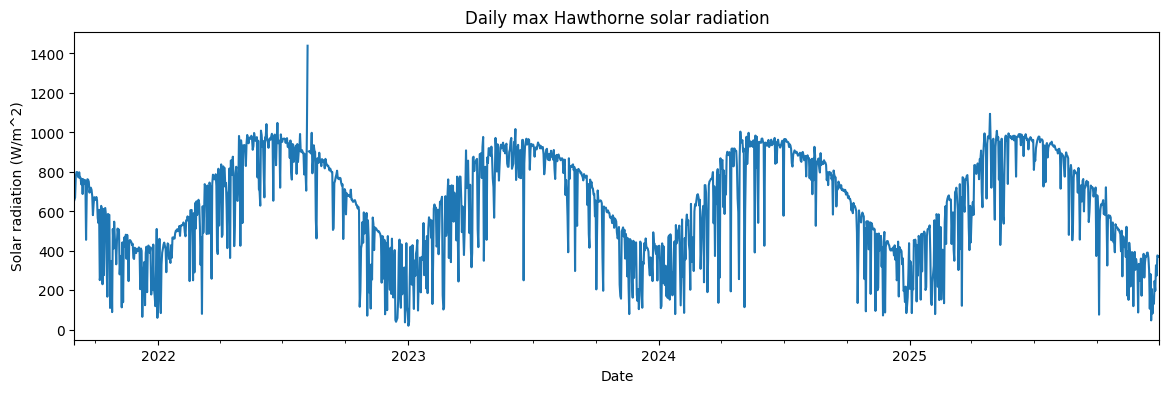

In [5]:
ax = combined_sr.resample("D").max().plot(figsize=(14, 4), title="Daily max Hawthorne solar radiation")
ax.set_xlabel("Date")
ax.set_ylabel("Solar radiation (W/m^2)");